**Clasificación de 10 categorías de Caltech 101: CNN desde cero y transferencia de aprendizaje**

Este experimento entrena dos redes para reconocer las mismas diez categorías: aviones (`airplanes`), motocicletas (`Motorbikes`), bonsáis (`bonsai`), cerebros (`brain`), mariposas (`butterfly`), candelabros (`chandelier`), veleros (`ketch`), leopardos (`Leopards`), revólveres (`revolver`) y girasoles (`sunflower`). Se construye una CNN básica con pesos aleatorios y se adapta MobileNetV2 con pesos preentrenados en ImageNet. Se evalúan ambas con matrices de confusión sobre exactamente las mismas imágenes de prueba.

La base original es [Caltech 101, publicada por CaltechDATA](https://data.caltech.edu/records/mzrjq-6wc02). El repositorio describe 101 categorías de objetos y cantidades diferentes de imágenes por categoría. Para que las categorías grandes no dominen este ejercicio, se seleccionan aleatoriamente 80 imágenes únicas de cada clase: 800 en total. No se utiliza `BACKGROUND_Google` ni el resto de categorías. Esta selección es una decisión del experimento, no el protocolo oficial completo de Caltech 101.

El notebook conserva las salidas de su ejecución. Para volver a entrenarlo en Google Colab, se carga este archivo `.ipynb` y se elige **Entorno de ejecución → Ejecutar todas**. Una GPU es opcional y puede activarse en **Cambiar tipo de entorno de ejecución**. La primera ejecución necesita internet para descargar el dataset y los pesos; no requiere subir archivos ni conectar Google Drive. Los resultados pueden variar ligeramente según las versiones y el hardware.

In [1]:
# Instalar sólo dependencias ausentes: Colab suele incluirlas.
import importlib.util
import subprocess
import sys

packages = {
    'tensorflow': 'tensorflow==2.20.0',
    'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
    'sklearn': 'scikit-learn', 'PIL': 'pillow',
}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Dependencias disponibles.')

Dependencias disponibles.


**Configuración y reproducibilidad.** La semilla controla la selección de imágenes, la partición y la inicialización. Se guardará un manifiesto con las rutas relativas, etiquetas, hashes y subconjuntos, para identificar qué imágenes participaron. Las versiones y el dispositivo se muestran como evidencia de esta ejecución. Se usa precisión de 32 bits y se limita el paralelismo de CPU para evitar saturar el equipo.

In [2]:
import os
from pathlib import Path

BASE = Path('/content/caltech101') if Path('/content').is_dir() else Path.cwd()
DATA = BASE / 'datos'
OUT = BASE / 'resultados'
DATA.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
os.environ['KERAS_HOME'] = str(BASE / '.keras')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '1'

import hashlib
import json
import platform
import shutil
import tarfile
import time
import urllib.request
import zipfile
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from IPython.display import display, Markdown

SEED = 42
CLASS_NAMES = ['airplanes', 'Motorbikes', 'bonsai', 'brain', 'butterfly',
               'chandelier', 'ketch', 'Leopards', 'revolver', 'sunflower']
N_PER_CLASS = 80
IMG_SIZE = 128
BATCH_SIZE = 32
EPOCHS_SCRATCH = 30
EPOCHS_HEAD = 15
EPOCHS_FINE = 5
try:
    tf.config.threading.set_intra_op_parallelism_threads(4)
    tf.config.threading.set_inter_op_parallelism_threads(2)
except RuntimeError:
    print('TensorFlow ya estaba inicializado; se conserva su configuración de hilos.')
tf.keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()

versions = {
    'python': platform.python_version(), 'tensorflow': tf.__version__,
    'keras': keras.__version__, 'numpy': np.__version__,
    'pandas': pd.__version__, 'scikit_learn': sklearn.__version__,
    'dispositivo': 'GPU' if tf.config.list_physical_devices('GPU') else 'CPU',
    'ejecucion_utc': datetime.now(timezone.utc).isoformat(),
    'semilla': SEED, 'tamano_imagen': IMG_SIZE,
}
print(json.dumps(versions, indent=2, ensure_ascii=False))

{
  "python": "3.12.10",
  "tensorflow": "2.20.0",
  "keras": "3.15.1",
  "numpy": "2.5.4",
  "pandas": "3.1.0",
  "scikit_learn": "1.9.1",
  "dispositivo": "CPU",
  "ejecucion_utc": "2026-11-03T03:31:46.449621+00:00",
  "semilla": 42,
  "tamano_imagen": 128
}


**Descarga de la fuente original.** Se comprueba el MD5 publicado por CaltechDATA para verificar que el ZIP descargado coincide con el archivo de referencia. Del contenedor se extrae sólo el archivo de imágenes, y de éste únicamente JPG de las diez categorías. No hacen falta las anotaciones de contornos para esta tarea de clasificación. Los nombres internos se validan antes de escribir archivos.

In [3]:
EXPECTED_MD5 = '3138e1922a9193bfa496528edbbc45d0'
archive = DATA / 'caltech-101.zip'

def file_hash(path, algorithm='sha256'):
    h = hashlib.new(algorithm)
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()

if not archive.exists() or file_hash(archive, 'md5') != EXPECTED_MD5:
    # El parámetro evita reutilizar redirecciones de descarga ya vencidas.
    url = ('https://data.caltech.edu/records/mzrjq-6wc02/files/'
           f'caltech-101.zip?download=1&fresh={time.time_ns()}')
    request = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    partial = archive.with_suffix('.zip.part')
    with urllib.request.urlopen(request, timeout=180) as response, partial.open('wb') as f:
        shutil.copyfileobj(response, f)
    if file_hash(partial, 'md5') != EXPECTED_MD5:
        raise ValueError('El ZIP no coincide con el MD5 publicado; no se extraerá.')
    partial.replace(archive)
assert file_hash(archive, 'md5') == EXPECTED_MD5

images_root = DATA / '101_ObjectCategories'
marker = DATA / 'seleccion_extraida_v1.txt'
if not marker.exists():
    with zipfile.ZipFile(archive) as z:
        names = [n for n in z.namelist()
                 if n.endswith('101_ObjectCategories.tar.gz') and '__MACOSX' not in n]
        if len(names) != 1:
            raise ValueError(f'Estructura del ZIP inesperada: {z.namelist()}')
        tar_path = DATA / '101_ObjectCategories.tar.gz'
        with z.open(names[0]) as source, tar_path.open('wb') as dest:
            shutil.copyfileobj(source, dest)
    with tarfile.open(tar_path, 'r:gz') as tar:
        for member in tar:
            parts = Path(member.name.replace('\\', '/')).parts
            if (not member.isfile() or '..' in parts or len(parts) != 3
                or parts[0] != '101_ObjectCategories'
                or parts[1] not in CLASS_NAMES
                or not parts[2].lower().endswith('.jpg')):
                continue
            target = images_root / parts[1] / parts[2]
            target.parent.mkdir(parents=True, exist_ok=True)
            with tar.extractfile(member) as source, target.open('wb') as dest:
                shutil.copyfileobj(source, dest)
    marker.write_text('Extracción de categorías seleccionadas completada.', encoding='utf-8')
assert all((images_root / name).is_dir() for name in CLASS_NAMES)
print('MD5 verificado:', EXPECTED_MD5)
print('Categorías disponibles:', ', '.join(CLASS_NAMES))

MD5 verificado: 3138e1922a9193bfa496528edbbc45d0
Categorías disponibles: airplanes, Motorbikes, bonsai, brain, butterfly, chandelier, ketch, Leopards, revolver, sunflower


**Selección y separación de datos.** Primero se comprueba que las imágenes se pueden leer y se eliminan duplicados exactos por SHA-256. Luego se eligen 80 por clase con semilla fija y se dividen de forma estratificada: 60 % para aprender los pesos, 20 % para elegir la mejor época y 20 % reservado para la evaluación final. Cada clase aporta 48 imágenes de entrenamiento, 16 de validación y 16 de prueba. Ninguna imagen seleccionada pertenece a dos subconjuntos. No se ha realizado una auditoría de fotografías visualmente parecidas o de posible solapamiento con los datos usados para preentrenar MobileNetV2.

In [4]:
rng = np.random.default_rng(SEED)
seen_hashes = set()
records, availability = [], []
for label, name in enumerate(CLASS_NAMES):
    valid = []
    for path in sorted((images_root / name).glob('*.jpg')):
        with Image.open(path) as image:
            image.convert('RGB').load()
        digest = file_hash(path)
        if digest in seen_hashes:
            continue
        seen_hashes.add(digest)
        valid.append((path, digest))
    availability.append({'clase': name, 'disponibles_unicas': len(valid),
                         'seleccionadas': N_PER_CLASS})
    if len(valid) < N_PER_CLASS:
        raise ValueError(f'{name}: sólo hay {len(valid)} imágenes válidas únicas.')
    for pos in rng.choice(len(valid), size=N_PER_CLASS, replace=False):
        path, digest = valid[int(pos)]
        records.append({'ruta': path.relative_to(images_root).as_posix(),
                        'clase': name, 'etiqueta': label, 'sha256': digest})

manifest = pd.DataFrame(records)
indices = np.arange(len(manifest))
labels = manifest['etiqueta'].to_numpy(dtype=np.int32)
train_idx, remaining_idx = train_test_split(
    indices, test_size=0.4, random_state=SEED, stratify=labels)
val_idx, test_idx = train_test_split(
    remaining_idx, test_size=0.5, random_state=SEED, stratify=labels[remaining_idx])
for name, idx in [('entrenamiento', train_idx), ('validacion', val_idx), ('prueba', test_idx)]:
    manifest.loc[idx, 'subconjunto'] = name
assert not (set(train_idx) & set(val_idx) or set(train_idx) & set(test_idx)
            or set(val_idx) & set(test_idx))
assert len(set(train_idx) | set(val_idx) | set(test_idx)) == len(manifest)
assert manifest.sha256.is_unique and manifest.subconjunto.notna().all()
manifest.to_csv(OUT / 'particiones.csv', index=False)
counts = pd.crosstab(manifest.clase, manifest.subconjunto).reindex(CLASS_NAMES)
display(pd.DataFrame(availability).set_index('clase').join(counts))
print(f'Totales: {len(train_idx)} entrenamiento, {len(val_idx)} validación, {len(test_idx)} prueba.')

,disponibles_unicas,seleccionadas,entrenamiento,prueba,validacion
clase,,,,,
airplanes,800,80,48,16,16
Motorbikes,798,80,48,16,16
bonsai,128,80,48,16,16
brain,98,80,48,16,16
butterfly,91,80,48,16,16
chandelier,107,80,48,16,16
ketch,114,80,48,16,16
Leopards,200,80,48,16,16
revolver,82,80,48,16,16


Totales: 480 entrenamiento, 160 validación, 160 prueba.


**Preparación de las entradas.** Se convierten las imágenes a RGB y se ajustan a 128 × 128 píxeles conservando su proporción con bordes negros. Ambas redes reciben esas mismas imágenes. La CNN usa valores entre 0 y 1; MobileNetV2 usa entre −1 y 1, según su preprocesamiento oficial. Durante el entrenamiento se aplican reflejos horizontales, pequeñas rotaciones y zoom. Estas transformaciones están dentro de los modelos y quedan desactivadas al validar o predecir.

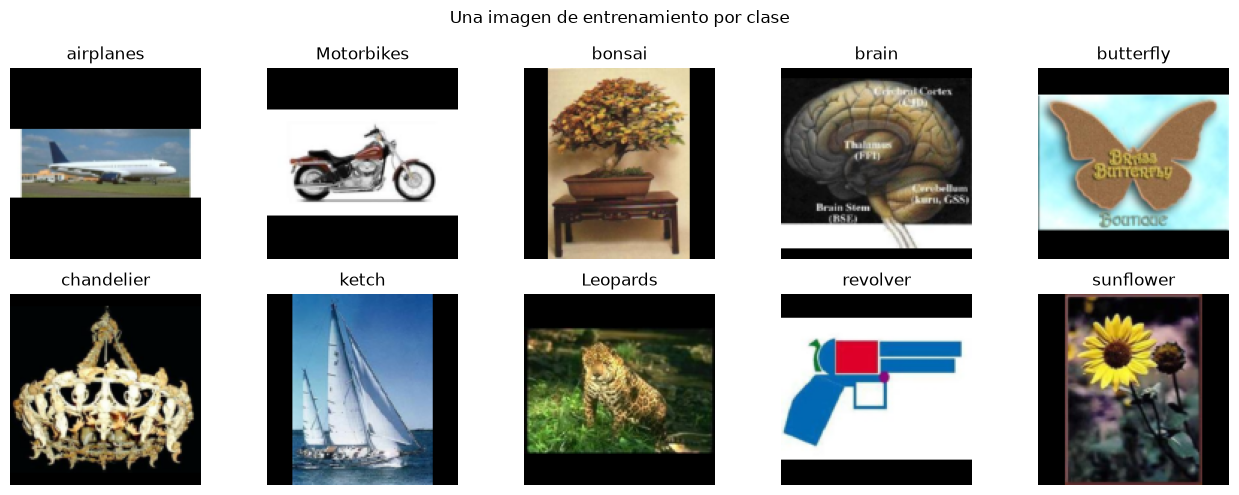

Forma: (800, 128, 128, 3) | Tipo: uint8


In [5]:
images = []
for relative in manifest.ruta:
    with Image.open(images_root / relative) as image:
        image = ImageOps.pad(image.convert('RGB'), (IMG_SIZE, IMG_SIZE),
                             method=Image.Resampling.BILINEAR, color=(0, 0, 0))
        images.append(np.asarray(image, dtype=np.uint8))
images = np.stack(images)

def dataset(idx, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images[idx], labels[idx]))
    if training:
        ds = ds.shuffle(len(idx), seed=SEED, reshuffle_each_iteration=True)
    options = tf.data.Options()
    options.experimental_deterministic = True
    options.threading.private_threadpool_size = 4
    return ds.batch(BATCH_SIZE).with_options(options).prefetch(1)

val_ds, test_ds = dataset(val_idx), dataset(test_idx)

def augmentation():
    return keras.Sequential([
        layers.RandomFlip('horizontal', seed=SEED),
        layers.RandomRotation(0.05, fill_mode='constant', seed=SEED + 1),
        layers.RandomZoom(0.08, fill_mode='constant', seed=SEED + 2),
    ], name='aumentos_solo_entrenamiento')

fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for label, ax in enumerate(axes.flat):
    # La muestra ilustrativa pertenece a entrenamiento.
    i = next(i for i in train_idx if labels[i] == label)
    ax.imshow(images[i]); ax.set_title(CLASS_NAMES[label]); ax.axis('off')
fig.suptitle('Una imagen de entrenamiento por clase')
fig.tight_layout(); fig.savefig(OUT / 'ejemplos_clases.png', dpi=150)
plt.show()
print('Forma:', images.shape, '| Tipo:', images.dtype)

**Red básica desde cero.** Se construye una CNN con tres convoluciones de 16, 32 y 64 filtros, cada una seguida de MaxPooling. La parte final aplana los mapas y usa una capa de 64 neuronas, Dropout y diez salidas softmax. Todos los pesos se inicializan aleatoriamente; no se carga ningún modelo previo. La entropía cruzada mide el error de clasificación y Adam actualiza los pesos. Se limita a 30 épocas, se reduce la tasa de aprendizaje si la validación se estanca y se conserva la época con menor pérdida de validación.

In [6]:
def callbacks(name, patience=6):
    return [
        keras.callbacks.ModelCheckpoint(str(OUT / f'{name}.weights.h5'),
            monitor='val_loss', save_best_only=True, save_weights_only=True),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=patience,
            restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
            patience=3, min_lr=1e-6),
    ]

tf.keras.utils.set_random_seed(SEED)
inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='imagen_rgb')
x = augmentation()(inputs)
x = layers.Rescaling(1.0 / 255)(x)
for filters in [16, 32, 64]:
    x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
    x = layers.MaxPooling2D()(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.35, seed=SEED)(x)
outputs = layers.Dense(len(CLASS_NAMES), activation='softmax')(x)
scratch = keras.Model(inputs, outputs, name='cnn_desde_cero')
scratch.compile(optimizer=keras.optimizers.Adam(1e-3),
                loss='sparse_categorical_crossentropy', metrics=['accuracy'])
scratch.summary()
started = time.perf_counter()
hist_scratch = scratch.fit(dataset(train_idx, training=True),
    validation_data=val_ds, epochs=EPOCHS_SCRATCH,
    callbacks=callbacks('cnn_mejor'), verbose=2)
seconds_scratch = time.perf_counter() - started
scratch.load_weights(OUT / 'cnn_mejor.weights.h5')
print(f'Tiempo de entrenamiento CNN: {seconds_scratch:.1f} segundos.')

Model: "cnn_desde_cero"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen_rgb (InputLayer)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumentos_solo_entrenamiento     │ (None, 128, 128, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,048,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,072,874 (4.09 MB)

 Trainable params: 1,072,874 (4.09 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


... (57 outputs left out)

15/15 - 3s - 219ms/step - accuracy: 0.8979 - loss: 0.2585 - val_accuracy: 0.7875 - val_loss: 0.8063 - learning_rate: 2.5000e-04


Epoch 30/30


15/15 - 3s - 216ms/step - accuracy: 0.9167 - loss: 0.2338 - val_accuracy: 0.8062 - val_loss: 0.7541 - learning_rate: 2.5000e-04


Tiempo de entrenamiento CNN: 108.8 segundos.

**Transfer learning: descargar y adaptar MobileNetV2.** `weights='imagenet'` descarga los pesos preentrenados; `include_top=False` retira su clasificador original. Se congela la base para entrenar una cabeza nueva con diez salidas. GlobalAveragePooling resume los mapas de características y una capa densa aprende a relacionarlos con estas etiquetas. Aquí “clases nuevas” significa las salidas de este ejercicio; no implica que los conceptos sean desconocidos para ImageNet. El procedimiento y el rango de entrada siguen el [tutorial oficial de TensorFlow](https://www.tensorflow.org/tutorials/images/transfer_learning).

In [7]:
tf.keras.utils.set_random_seed(SEED)
download_started = time.perf_counter()
base = keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights='imagenet')
print(f'Carga/descarga de pesos: {time.perf_counter() - download_started:.1f} segundos.')
base.trainable = False
inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3), name='imagen_rgb')
x = augmentation()(inputs)
x = layers.Rescaling(1.0 / 127.5, offset=-1, name='preprocesamiento_mobilenet')(x)
# training=False conserva las estadísticas de BatchNormalization.
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.3, seed=SEED)(x)
outputs = layers.Dense(len(CLASS_NAMES), activation='softmax')(x)
transfer = keras.Model(inputs, outputs, name='mobilenetv2_transfer')
transfer.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])
transfer.summary()
started = time.perf_counter()
hist_head = transfer.fit(dataset(train_idx, training=True), validation_data=val_ds,
    epochs=EPOCHS_HEAD, callbacks=callbacks('transfer_cabeza', patience=4), verbose=2)
seconds_head = time.perf_counter() - started
transfer.load_weights(OUT / 'transfer_cabeza.weights.h5')
head_val_loss = min(hist_head.history['val_loss'])
print(f'Tiempo entrenando la cabeza: {seconds_head:.1f} segundos.')

Carga/descarga de pesos: 2.3 segundos.


Model: "mobilenetv2_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen_rgb (InputLayer)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumentos_solo_entrenamiento     │ (None, 128, 128, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ preprocesamiento_mobilenet      │ (None, 128, 128, 3)    │             0 │
│ (Rescaling)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,618 (8.93 MB)

 Trainable params: 82,634 (322.79 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

... (23 outputs left out)

15/15 - 8s - 524ms/step - accuracy: 0.9896 - loss: 0.0463 - val_accuracy: 0.9750 - val_loss: 0.0518 - learning_rate: 0.0010


Epoch 13/15


15/15 - 8s - 502ms/step - accuracy: 0.9937 - loss: 0.0354 - val_accuracy: 0.9875 - val_loss: 0.0417 - learning_rate: 5.0000e-04


Tiempo entrenando la cabeza: 122.5 segundos.


**Ajuste fino.** Después de aprender la cabeza se permite modificar únicamente las últimas 20 capas de la base, manteniendo congeladas sus capas BatchNormalization. Se recompila con una tasa de aprendizaje menor, 0.00001, y se entrena hasta cinco épocas adicionales. Esto adapta también parte de las características preentrenadas. Se conserva el ajuste fino sólo si mejora la pérdida de validación respecto a la cabeza congelada; el conjunto de prueba no participa en esta decisión. El tratamiento de BatchNormalization y la recompilación siguen la [guía de transferencia de Keras/TensorFlow](https://www.tensorflow.org/guide/keras/transfer_learning).

In [8]:
base.trainable = True
for layer in base.layers:
    layer.trainable = False
for layer in base.layers[-20:]:
    if not isinstance(layer, layers.BatchNormalization):
        layer.trainable = True
transfer.compile(optimizer=keras.optimizers.Adam(1e-5),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])
trainable_parameters = int(sum(np.prod(w.shape) for w in transfer.trainable_weights))
print('Parámetros entrenables durante ajuste fino:', trainable_parameters)
started = time.perf_counter()
hist_fine = transfer.fit(dataset(train_idx, training=True), validation_data=val_ds,
    epochs=EPOCHS_FINE, callbacks=callbacks('transfer_fino', patience=3), verbose=2)
seconds_fine = time.perf_counter() - started
if min(hist_fine.history['val_loss']) < head_val_loss:
    selected_phase = 'ajuste fino'
    transfer.load_weights(OUT / 'transfer_fino.weights.h5')
else:
    selected_phase = 'cabeza con base congelada'
    transfer.load_weights(OUT / 'transfer_cabeza.weights.h5')
seconds_transfer = seconds_head + seconds_fine
print('Modelo elegido por validación:', selected_phase)
print(f'Tiempo de entrenamiento de transferencia: {seconds_transfer:.1f} segundos.')

Parámetros entrenables durante ajuste fino: 1277514
Epoch 1/5


15/15 - 28s - 2s/step - accuracy: 0.9833 - loss: 0.0685 - val_accuracy: 0.9875 - val_loss: 0.0304 - learning_rate: 1.0000e-05


Epoch 2/5


15/15 - 9s - 632ms/step - accuracy: 0.9812 - loss: 0.0595 - val_accuracy: 0.9875 - val_loss: 0.0295 - learning_rate: 1.0000e-05


Epoch 3/5


15/15 - 8s - 547ms/step - accuracy: 0.9896 - loss: 0.0423 - val_accuracy: 0.9875 - val_loss: 0.0297 - learning_rate: 1.0000e-05


Epoch 4/5


15/15 - 9s - 631ms/step - accuracy: 0.9875 - loss: 0.0546 - val_accuracy: 0.9875 - val_loss: 0.0285 - learning_rate: 1.0000e-05


Epoch 5/5


15/15 - 9s - 616ms/step - accuracy: 0.9958 - loss: 0.0204 - val_accuracy: 0.9875 - val_loss: 0.0206 - learning_rate: 1.0000e-05


Modelo elegido por validación: ajuste fino
Tiempo de entrenamiento de transferencia: 186.9 segundos.


**Curvas de aprendizaje.** La exactitud indica la proporción de aciertos y la pérdida mide el error que minimiza el entrenamiento. Una separación creciente entre entrenamiento y validación puede indicar sobreajuste. En la gráfica de transferencia la línea vertical señala el comienzo del ajuste fino; la evaluación final usa el mejor checkpoint elegido por validación, no necesariamente la última época dibujada.

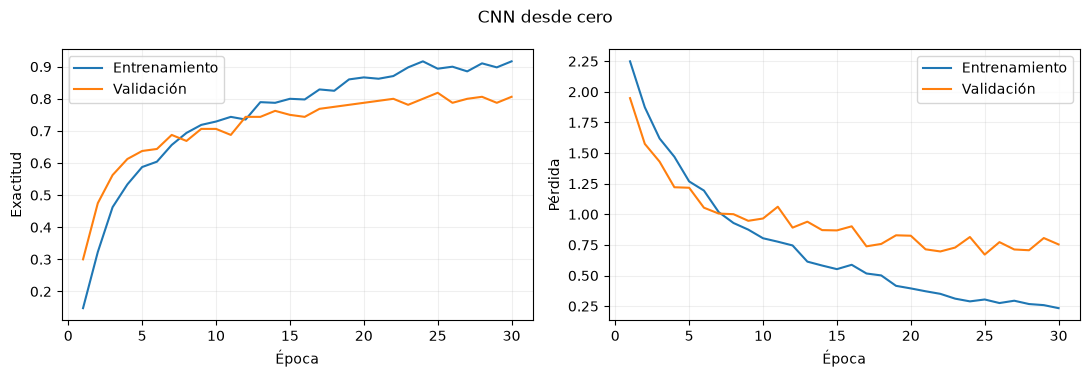

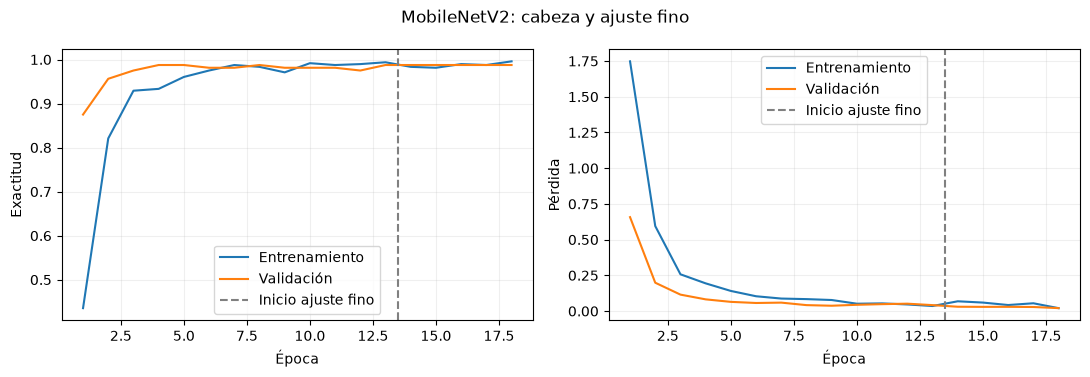

In [9]:
def plot_history(history, title, path, fine_start=None):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, key, ylabel in zip(axes, ['accuracy', 'loss'], ['Exactitud', 'Pérdida']):
        epochs = np.arange(1, len(history[key]) + 1)
        ax.plot(epochs, history[key], label='Entrenamiento')
        ax.plot(epochs, history['val_' + key], label='Validación')
        if fine_start is not None:
            ax.axvline(fine_start + 0.5, color='gray', linestyle='--', label='Inicio ajuste fino')
        ax.set(xlabel='Época', ylabel=ylabel); ax.legend(); ax.grid(alpha=0.2)
    fig.suptitle(title); fig.tight_layout()
    fig.savefig(path, dpi=150); plt.show()

combined_history = {key: hist_head.history[key] + hist_fine.history[key]
                    for key in ['accuracy', 'val_accuracy', 'loss', 'val_loss']}
plot_history(hist_scratch.history, 'CNN desde cero', OUT / 'curvas_cnn.png')
plot_history(combined_history, 'MobileNetV2: cabeza y ajuste fino',
             OUT / 'curvas_transfer.png', fine_start=len(hist_head.history['loss']))
pd.DataFrame(hist_scratch.history).to_csv(OUT / 'historial_cnn.csv', index_label='epoca_base_0')
pd.DataFrame(combined_history).to_csv(OUT / 'historial_transfer.csv', index_label='epoca_base_0')

**Evaluación final y matrices de confusión.** Ahora se utiliza por primera vez el conjunto de prueba para medir desempeño. No se baraja ni se aumentan sus imágenes. Las filas de cada matriz corresponden a la clase real y las columnas a la predicha: la diagonal cuenta aciertos y las demás celdas muestran confusiones. Se presenta una matriz de conteos por red y otra normalizada por fila para leer porcentajes dentro de cada categoría, siguiendo la [definición de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html).

También se calcula exactitud y F1 macro. F1 combina precisión y sensibilidad; su promedio macro da el mismo peso a cada categoría. Los reportes por clase muestran precisión, recall, F1 y número de imágenes evaluadas. Una comparación con una sola semilla y una muestra reducida describe este experimento, pero no establece una superioridad universal ni mide generalización a otros datasets.

CNN desde cero


,precision,recall,f1-score,support
airplanes,0.9412,1.0000,0.9697,16.0000
Motorbikes,0.8824,0.9375,0.9091,16.0000
bonsai,0.8462,0.6875,0.7586,16.0000
brain,0.6522,0.9375,0.7692,16.0000
butterfly,0.8462,0.6875,0.7586,16.0000
chandelier,0.6154,0.5000,0.5517,16.0000
ketch,0.6842,0.8125,0.7429,16.0000
Leopards,1.0000,0.8125,0.8966,16.0000
revolver,0.8333,0.9375,0.8824,16.0000
sunflower,1.0000,0.8750,0.9333,16.0000


MobileNetV2 transferencia


,precision,recall,f1-score,support
airplanes,1.0,1.0,1.0,16.0
Motorbikes,1.0,1.0,1.0,16.0
bonsai,1.0,1.0,1.0,16.0
brain,1.0,1.0,1.0,16.0
butterfly,1.0,1.0,1.0,16.0
chandelier,1.0,1.0,1.0,16.0
ketch,1.0,1.0,1.0,16.0
Leopards,1.0,1.0,1.0,16.0
revolver,1.0,1.0,1.0,16.0
sunflower,1.0,1.0,1.0,16.0


,exactitud,f1_macro,aciertos,imagenes_prueba
modelo,,,,
CNN desde cero,0.8188,0.8172,131,160
MobileNetV2 transferencia,1.0000,1.0000,160,160


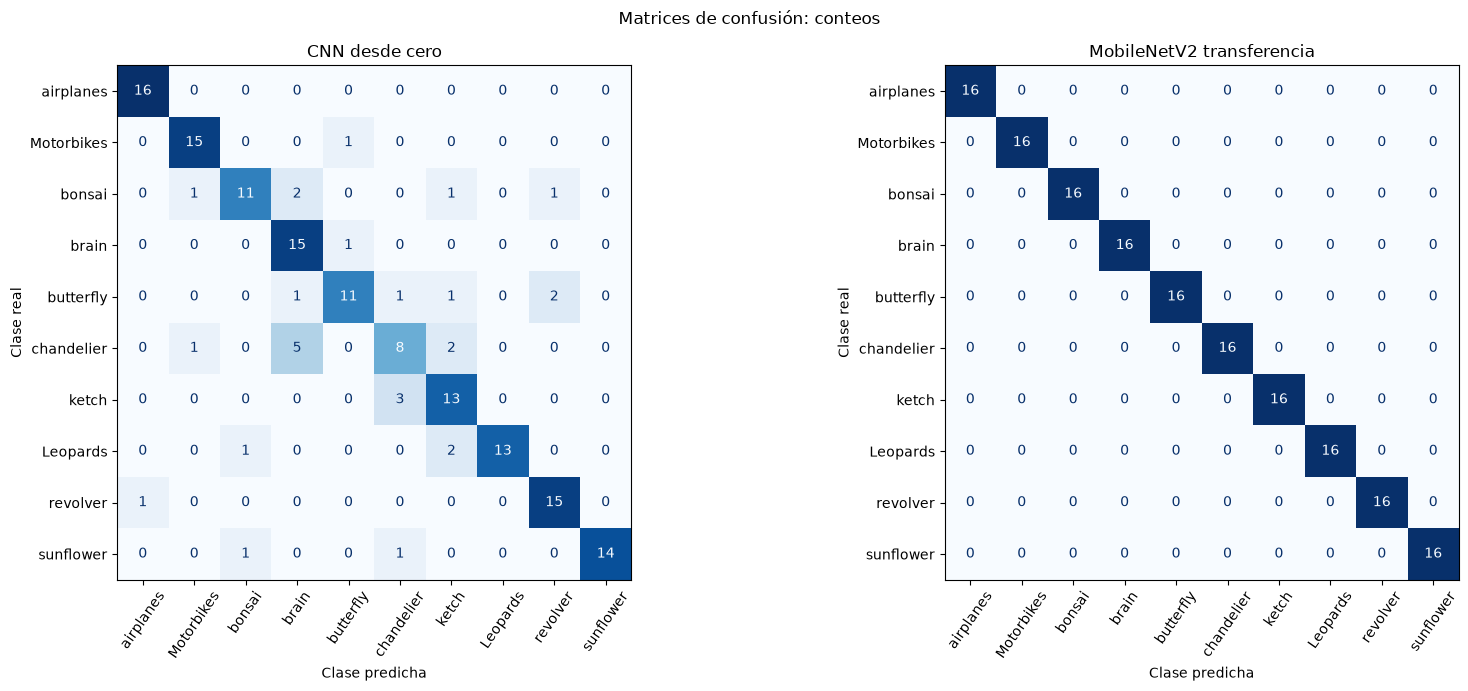

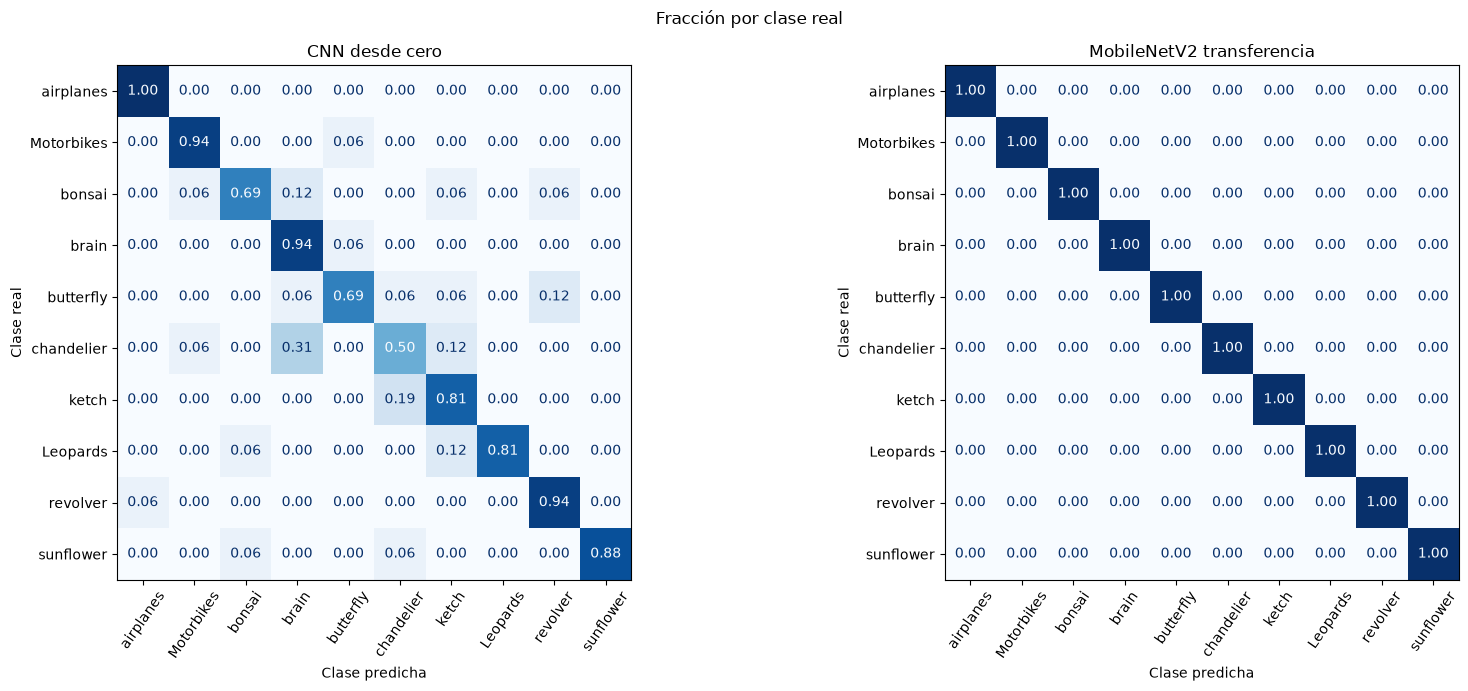

In [10]:
y_true = labels[test_idx]
models = {'CNN desde cero': scratch, 'MobileNetV2 transferencia': transfer}
predictions, matrices, scores = {}, {}, []
model_files = {'CNN desde cero': 'cnn', 'MobileNetV2 transferencia': 'transfer'}
for name, model in models.items():
    probabilities = model.predict(test_ds, verbose=0)
    assert probabilities.shape == (len(test_idx), len(CLASS_NAMES))
    assert np.isfinite(probabilities).all()
    pred = probabilities.argmax(axis=1)
    predictions[name] = pred
    matrix = confusion_matrix(y_true, pred, labels=np.arange(len(CLASS_NAMES)))
    matrices[name] = matrix
    assert matrix.shape == (10, 10) and matrix.sum() == len(test_idx)
    assert np.all(matrix.sum(axis=1) == 16)
    scores.append({'modelo': name, 'exactitud': accuracy_score(y_true, pred),
                   'f1_macro': f1_score(y_true, pred, average='macro', zero_division=0),
                   'aciertos': int((y_true == pred).sum()), 'imagenes_prueba': len(test_idx)})
    report = classification_report(y_true, pred, labels=np.arange(10),
        target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    print(name)
    display(pd.DataFrame(report).T.round(4))
    slug = model_files[name]
    pd.DataFrame(report).T.to_csv(OUT / f'reporte_{slug}.csv')
    pd.DataFrame(matrix, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(OUT / f'matriz_{slug}.csv')

metrics = pd.DataFrame(scores).set_index('modelo')
display(metrics.round(4))
metrics.to_csv(OUT / 'comparacion.csv')
for normalized in [False, True]:
    fig, axes = plt.subplots(1, 2, figsize=(17, 7))
    for ax, (name, matrix) in zip(axes, matrices.items()):
        values = matrix / matrix.sum(axis=1, keepdims=True) if normalized else matrix
        ConfusionMatrixDisplay(values, display_labels=CLASS_NAMES).plot(
            ax=ax, cmap='Blues', values_format='.2f' if normalized else 'd',
            xticks_rotation=55, colorbar=False)
        ax.set_title(name); ax.set_xlabel('Clase predicha'); ax.set_ylabel('Clase real')
        if normalized:
            ax.images[0].set_clim(0, 1)
        else:
            ax.images[0].set_clim(0, 16)
    fig.suptitle('Fracción por clase real' if normalized else 'Matrices de confusión: conteos')
    fig.tight_layout()
    fig.savefig(OUT / ('matrices_normalizadas.png' if normalized else 'matrices_conteos.png'), dpi=160)
    plt.show()

test_results = manifest.iloc[test_idx].copy()
for name, pred in predictions.items():
    test_results[model_files[name] + '_prediccion'] = [CLASS_NAMES[i] for i in pred]
test_results.to_csv(OUT / 'predicciones_prueba.csv', index=False)

**Interpretación obtenida de los resultados.** La siguiente celda redacta la comparación usando las predicciones reales y señala la confusión fuera de la diagonal más frecuente. Sus cifras se recalculan si se repite el entrenamiento. No se modifica ningún hiperparámetro a partir de estos resultados de prueba.

In [11]:
a = metrics.loc['CNN desde cero', 'exactitud']
b = metrics.loc['MobileNetV2 transferencia', 'exactitud']
delta = 100 * (b - a)
if delta > 0:
    comparison = f'MobileNetV2 obtuvo {delta:.2f} puntos porcentuales más de exactitud.'
elif delta < 0:
    comparison = f'La CNN desde cero obtuvo {-delta:.2f} puntos porcentuales más de exactitud.'
else:
    comparison = 'Ambas redes obtuvieron la misma exactitud.'
paragraphs = [
    f'En las {len(test_idx)} imágenes de prueba reservadas, la CNN desde cero acertó '
    f'{metrics.loc["CNN desde cero", "aciertos"]:.0f} ({a:.2%}) y MobileNetV2 acertó '
    f'{metrics.loc["MobileNetV2 transferencia", "aciertos"]:.0f} ({b:.2%}). '
    f'{comparison} El F1 macro fue {metrics.iloc[0].f1_macro:.4f} y '
    f'{metrics.iloc[1].f1_macro:.4f}, respectivamente.'
]
for name, matrix in matrices.items():
    errors = matrix.copy(); np.fill_diagonal(errors, 0)
    if errors.max() > 0:
        real, predicted = np.unravel_index(errors.argmax(), errors.shape)
        paragraphs.append(f'Para {name}, una de las confusiones más frecuentes fue '
            f'{CLASS_NAMES[real]} → {CLASS_NAMES[predicted]}, con {errors[real, predicted]} casos.')
    else:
        paragraphs.append(f'{name} no presentó errores en esta muestra de prueba.')
paragraphs.append(f'En transferencia se eligió la fase de {selected_phase} según la pérdida '
    'de validación. El conocimiento previo de ImageNet y la arquitectura son diferencias '
    'entre las redes: esta comparación práctica no aísla el efecto de preentrenar una '
    'misma arquitectura. Se necesitarían más particiones o semillas para estudiar estabilidad.')
conclusion = '\n\n'.join(paragraphs)
display(Markdown(conclusion))
(OUT / 'conclusiones.txt').write_text(conclusion, encoding='utf-8')

En las 160 imágenes de prueba reservadas, la CNN desde cero acertó 131 (81.88%) y MobileNetV2 acertó 160 (100.00%). MobileNetV2 obtuvo 18.13 puntos porcentuales más de exactitud. El F1 macro fue 0.8172 y 1.0000, respectivamente.

Para CNN desde cero, una de las confusiones más frecuentes fue chandelier → brain, con 5 casos.

MobileNetV2 transferencia no presentó errores en esta muestra de prueba.

En transferencia se eligió la fase de ajuste fino según la pérdida de validación. El conocimiento previo de ImageNet y la arquitectura son diferencias entre las redes: esta comparación práctica no aísla el efecto de preentrenar una misma arquitectura. Se necesitarían más particiones o semillas para estudiar estabilidad.

722

**Conservar el trabajo.** Además de las salidas visibles del notebook, se guardan los dos modelos completos en formato `.keras`, las particiones, predicciones, reportes, matrices en CSV y gráficas PNG. Los modelos aceptan imágenes RGB de 128 × 128 con valores de 0 a 255 e incluyen su normalización. El archivo `configuracion.json` conserva el orden de las clases, necesario para interpretar las diez salidas. Al terminar se crea un ZIP con los resultados; en Colab se puede descargar desde el panel **Archivos**. Para conservar un nuevo entrenamiento con sus salidas también hay que guardar o descargar el notebook desde **Archivo**.

In [12]:
scratch.save(OUT / 'cnn_desde_cero.keras')
transfer.save(OUT / 'mobilenetv2_transfer.keras')
for model, filename in [(scratch, 'cnn_desde_cero.keras'),
                        (transfer, 'mobilenetv2_transfer.keras')]:
    restored = keras.models.load_model(OUT / filename, compile=False)
    sample = images[test_idx[:4]]
    np.testing.assert_allclose(model(sample, training=False).numpy(),
        restored(sample, training=False).numpy(), rtol=1e-5, atol=1e-6)
print('Los dos modelos exportados se recargaron y conservaron sus predicciones.')
configuration = dict(versions, clases=CLASS_NAMES, imagenes_por_clase=N_PER_CLASS,
    proporciones={'entrenamiento': 0.6, 'validacion': 0.2, 'prueba': 0.2},
    epocas_cnn=len(hist_scratch.history['loss']), epocas_cabeza=len(hist_head.history['loss']),
    epocas_ajuste_fino=len(hist_fine.history['loss']), fase_elegida=selected_phase,
    segundos_cnn=seconds_scratch, segundos_transfer=seconds_transfer,
    url_datos='https://data.caltech.edu/records/mzrjq-6wc02', md5_dataset=EXPECTED_MD5)
(OUT / 'configuracion.json').write_text(json.dumps(configuration, indent=2,
    ensure_ascii=False), encoding='utf-8')
shutil.make_archive(str(BASE / 'resultados_caltech101'), 'zip', root_dir=OUT)
print('Modelos y resultados guardados. ZIP:', BASE / 'resultados_caltech101.zip')
print('Notebook terminado sin celdas de error.')

Los dos modelos exportados se recargaron y conservaron sus predicciones.


Modelos y resultados guardados. ZIP: .\caltech101_colab\resultados_caltech101.zip
Notebook terminado sin celdas de error.
